# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 36: Análise Exploratória dos Picos DEMON — LARGE Acertadas × Erradas

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

**Tarefa 1 (reunião de 26/10/2026), com a segunda representação.** O NB35 comparou o LOFAR de gravações acertadas e erradas. Aqui fazemos o mesmo com o **DEMON**, que mede outra propriedade física: a **modulação** do ruído de cavitação da hélice pela rotação do eixo e pela passagem das pás. Para navios, essas linhas ficam tipicamente entre 1 e 25 Hz, e a sua frequência depende da rotação, que tende a ser menor em navios maiores.

**Dados.** DEMON do projeto (`data/iara_processed/demon_features`):
- passa-faixa de 1–2 kHz e envelope pelo valor absoluto;
- reamostragem para 50 Hz e FFT de 512 pontos (janelas de 10,24 s, passo de 5,12 s);
- 253 faixas de 0,098 Hz, de 0,39 a 25 Hz;
- amplitude normalizada por gravação, então não há nível absoluto.

**Pré-processamento.** Cada espectro é dividido pelo fundo estimado com o mesmo TPSW do HCNN DEMON (±1,56 Hz, sem as ±0,29 Hz centrais) e convertido em **dB acima do fundo**, como no LOFAR.

**Modelo de referência.** O BiGRU DEMON (`bigru_att_demon_h64_s15-5_e20_4c`), o melhor modelo DEMON do projeto (SP 55,5, contra ~66 dos modelos LOFAR). Os modelos DEMON são bem mais fracos que os LOFAR, então os rótulos de acerto e erro são mais ruidosos. Para robustez, o consenso exige o mesmo resultado no MLP e no HCNN DEMON.

**Diferença em relação ao NB35.** Cada navio tem as suas linhas de modulação em frequências próprias. Na média faixa a faixa entre navios, essas linhas se espalham e somem, então a análise se concentra no **pico dominante de cada gravação**.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.ndimage as ndi
from scipy.stats import mannwhitneyu, false_discovery_control, spearmanr
try:
    from IPython.display import display
except ImportError:
    display = print

for _p in ('.', 'src', 'notebooks', 'notebooks/src'):
    if os.path.exists(os.path.join(_p, 'iara_results.py')) and os.path.abspath(_p) not in sys.path:
        sys.path.insert(0, os.path.abspath(_p))
import iara_results as R

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 10, 'figure.dpi': 120})
pd.set_option('display.precision', 2); pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

CLASSE = 'LARGE'
CLS = dict(enumerate(R.CLASSES)); CID = {v: k for k, v in CLS.items()}
C = CID[CLASSE]
MODELO = 'bigru_att_demon_h64_s15-5_e20_4c'               # melhor modelo DEMON do projeto (SP 55,5)
OUTROS = {'MLP DEMON': 'mlp_demon_h32-16_e30_4c', 'HCNN DEMON': 'hcnn_demon_tpsw_med5_e60p8_4c'}
DEMON_DIR = os.path.join(R.ROOT, 'data', 'iara_processed', 'demon_features')
CACHE = os.path.join(R.ROOT, 'data', 'iara_processed', 'cache_demon_relativo.pkl')

def fundo_tpsw(x, n=16, g=3, alpha=2.0):
    # mesmo TPSW do HCNN DEMON (scratch/eval_demon_harmonic_cnn_5x2cv.py): média de ±16 faixas (±1,56 Hz) sem as
    # ±3 centrais (±0,29 Hz); valores acima de 2x a primeira estimativa são cortados e a média é refeita
    k = np.ones(2 * n + 1); k[n - g:n + g + 1] = 0; k /= k.sum()
    b1 = ndi.convolve1d(x, k, axis=-1, mode='reflect')
    return ndi.convolve1d(np.where(x > alpha * b1, b1, x), k, axis=-1, mode='reflect')

if os.path.exists(CACHE):
    _c = pd.read_pickle(CACHE)
else:
    _med, _pers = {}, {}
    for f in os.listdir(DEMON_DIR):
        if not f.endswith('.pkl'):
            continue
        i = int(f[:-4]); d = pd.read_pickle(os.path.join(DEMON_DIR, f))
        avg, W = d['avg_spectrum'], d['df'].values
        _med[i] = 20 * np.log10(avg / (fundo_tpsw(avg) + 1e-12))                 # espectro médio, dB acima do fundo
        Wm = ndi.median_filter(W, size=(5, 1), mode='nearest')                   # mediana de 5 janelas (~25 s)
        _pers[i] = (20 * np.log10(Wm / (fundo_tpsw(Wm) + 1e-12)) > 6).mean(0)   # fração das janelas > 6 dB
    _c = {'freqs': d['frequencies'], 'medio': pd.DataFrame(_med).T.sort_index(), 'pers6': pd.DataFrame(_pers).T.sort_index()}
    pd.to_pickle(_c, CACHE)
FD = np.asarray(_c['freqs']); SD = _c['medio']; PD = _c['pers6']; DF = FD[1] - FD[0]

meta = pd.read_csv(os.path.join(R.ROOT, 'src', 'iara', 'dataset_info', 'iara.csv'), dtype={'Ship ID': str, 'ID': str})
meta['Ship ID'] = meta['Ship ID'].str.strip()
meta['Length'] = pd.to_numeric(meta['Length'], errors='coerce')
meta = meta.set_index(meta.ID.astype(int))
LAB = pd.concat(R.file_predictions(MODELO).values()).groupby('File').Target.first(); LAB.index = LAB.index.astype(int)
print(f'{len(SD)} gravações com DEMON; {len(FD)} faixas de {DF:.4f} Hz, de {FD[0]:.2f} a {FD[-1]:.0f} Hz')

1706 gravações com DEMON; 253 faixas de 0.0977 Hz, de 0.39 a 25 Hz


## 0. Rótulos de acerto e erro, e destino dos erros

**Acertada** = acerta em todos os folds de teste do BiGRU DEMON; **errada** = erra em todos; **oscila** = o resto. As erradas são separadas pela classe para onde vão na maioria dos folds.

In [2]:
def taxa_acerto(exp, c):
    # fração dos folds de teste em que a gravação da classe c foi acertada (voto majoritário por gravação)
    d = pd.concat(R.file_predictions(exp).values()); d = d[d.Target == c]
    t = d.groupby('File').apply(lambda x: (x.Prediction == x.Target).mean(), include_groups=False); t.index = t.index.astype(int)
    return t

def grupo(t):
    return pd.Series(np.where(t == 1, 'acertada', np.where(t == 0, 'errada', 'oscila')), index=t.index)

_t = taxa_acerto(MODELO, C)
T = pd.DataFrame({'BiGRU DEMON': _t, **{k: taxa_acerto(v, C) for k, v in OUTROS.items()}})
T['grupo'] = grupo(_t)
_todos = T[['BiGRU DEMON'] + list(OUTROS)]
T['consenso'] = np.where((_todos == 1).all(1), 'acertada', np.where((_todos == 0).all(1), 'errada', 'outro'))
_d = pd.concat(R.file_predictions(MODELO).values()); _d = _d[_d.Target == C].copy(); _d['File'] = _d.File.astype(int)
T['destino'] = _d[_d.Prediction != C].groupby('File').Prediction.agg(lambda x: x.value_counts().index[0]).map(CLS).reindex(T.index)
T['subgrupo'] = np.where(T.grupo == 'errada', 'errada→' + T.destino.fillna('?'), T.grupo)
T = T.join(meta[['Ship ID', 'Dataset', 'DETAILED TYPE', 'Length']])
DESTINO = (_d[_d.Prediction != C].Prediction.map(CLS).value_counts(normalize=True) * 100).round(1)
NAV_DEST = T[T.grupo == 'errada'].groupby('destino')['Ship ID'].nunique().sort_values(ascending=False)
DESTS = [x for x in NAV_DEST.index if NAV_DEST[x] >= 8]               # destinos com pelo menos 8 navios
SUBS = ['acertada'] + [f'errada→{x}' for x in DESTS]
CONT = pd.DataFrame({'BiGRU DEMON': T.grupo.value_counts(), 'consenso BiGRU+MLP+HCNN': pd.Series(T.consenso).value_counts()}).fillna(0).astype(int)
RESUMO_SUB = T.groupby('subgrupo').agg(gravações=('grupo', 'size'), navios=('Ship ID', 'nunique'))
print(f'{CLASSE}: {len(T)} gravações de {T["Ship ID"].nunique()} navios'); display(CONT)
print('Destino dos erros do BiGRU DEMON (%):'); display(DESTINO.to_frame('%'))
print('Subgrupos:'); display(RESUMO_SUB)

LARGE: 572 gravações de 417 navios


,BiGRU DEMON,consenso BiGRU+MLP+HCNN
acertada,265,171
errada,121,71
oscila,186,0
outro,0,330


Destino dos erros do BiGRU DEMON (%):


,%
Prediction,
SMALL,52.0
MEDIUM,30.3
BACKGROUND,17.7


Subgrupos:


,gravações,navios
subgrupo,,
acertada,265,214
errada→BACKGROUND,23,23
errada→MEDIUM,42,37
errada→SMALL,56,52
oscila,186,148


**Leitura.**
- 572 gravações LARGE de 417 navios: 265 acertadas, 186 oscilam e 121 erradas. No consenso dos três modelos DEMON: 171 acertadas e 71 erradas.
- Destino dos erros: SMALL 52,0%, MEDIUM 30,3%, BACKGROUND 17,7%. Subgrupos analisados (destinos com pelo menos 8 navios): **errada→SMALL**: 56 gravações de 52 navios; **errada→MEDIUM**: 42 gravações de 37 navios; **errada→BACKGROUND**: 23 gravações de 23 navios.

## 1. Espectro médio e comparação faixa a faixa

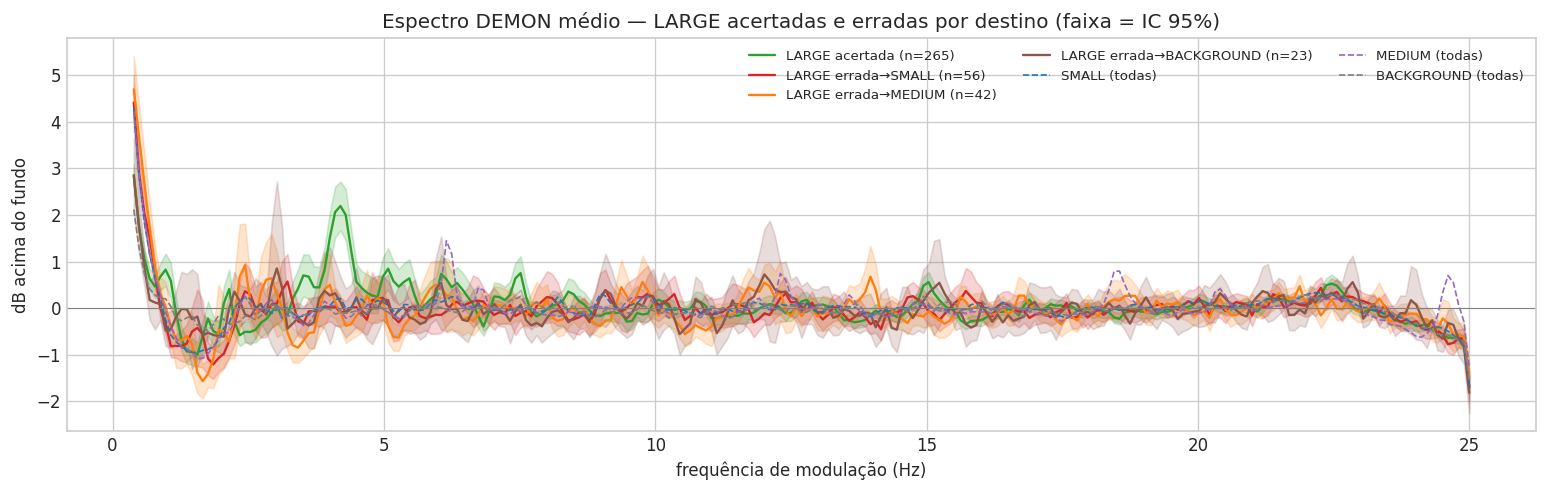

Faixa a faixa (253 faixas), por navio:


,navios,"faixas com q < 0,05","AUC mais longe de 0,5",em (Hz)
comparação,,,,
SMALL × MEDIUM,87 × 82,0,0.38,3.52
MEDIUM × LARGE,82 × 417,2,0.31,0.39
SMALL × LARGE,87 × 417,8,0.32,0.39
LARGE acertada × errada→SMALL,214 × 52,10,0.73,0.68
LARGE acertada × errada→MEDIUM,214 × 37,4,0.77,0.49
LARGE acertada × errada→BACKGROUND,214 × 23,1,0.74,2.34


In [3]:
# Espectro DEMON médio (dB acima do fundo TPSW) por subgrupo e por classe
fig, ax = plt.subplots(figsize=(13, 4.2))
cores = dict(zip(SUBS, ['tab:green', 'tab:red', 'tab:orange', 'tab:brown']))
for s in SUBS:
    X = SD.loc[T.index[T.subgrupo == s]]
    m, se = X.mean().values, X.std().values / np.sqrt(len(X))
    ax.plot(FD, m, color=cores[s], lw=1.4, label=f'{CLASSE} {s} (n={len(X)})')
    ax.fill_between(FD, m - 1.96 * se, m + 1.96 * se, color=cores[s], alpha=0.2)
for c, cor in (('SMALL', 'tab:blue'), ('MEDIUM', 'tab:purple'), ('LARGE', 'k'), ('BACKGROUND', 'tab:gray')):
    if c != CLASSE:
        ax.plot(FD, SD.loc[LAB.index[LAB == CID[c]]].mean().values, color=cor, lw=1, ls='--', label=f'{c} (todas)')
ax.axhline(0, color='gray', lw=0.6); ax.set_xlabel('frequência de modulação (Hz)'); ax.set_ylabel('dB acima do fundo')
ax.set_title(f'Espectro DEMON médio — {CLASSE} acertadas e erradas por destino (faixa = IC 95%)'); ax.legend(fontsize=8, ncol=3)
plt.tight_layout(); plt.show()

# Comparação faixa a faixa entre as classes (médias por navio, Mann-Whitney + FDR)
def nav(ids, X=SD):
    return X.loc[ids].groupby(meta.loc[ids, 'Ship ID'].values).mean()
def compara(ids_a, ids_b):
    A, B = nav(ids_a), nav(ids_b)
    U, p = mannwhitneyu(B.values, A.values, axis=0); q = false_discovery_control(p); auc = U / (len(A) * len(B))
    return len(A), len(B), int((q < 0.05).sum()), auc
_rows = []
for a, b in (('SMALL', 'MEDIUM'), ('MEDIUM', 'LARGE'), ('SMALL', 'LARGE')):
    na, nb, ns_, auc = compara(LAB.index[LAB == CID[a]], LAB.index[LAB == CID[b]])
    _rows.append({'comparação': f'{a} × {b}', 'navios': f'{na} × {nb}', 'faixas com q < 0,05': ns_,
                  'AUC mais longe de 0,5': auc[np.abs(auc - 0.5).argmax()], 'em (Hz)': FD[np.abs(auc - 0.5).argmax()]})
for s in SUBS[1:]:
    na, nb, ns_, auc = compara(T.index[T.subgrupo == 'acertada'], T.index[T.subgrupo == s])
    _rows.append({'comparação': f'{CLASSE} acertada × {s}', 'navios': f'{na} × {nb}', 'faixas com q < 0,05': ns_,
                  'AUC mais longe de 0,5': auc[np.abs(auc - 0.5).argmax()], 'em (Hz)': FD[np.abs(auc - 0.5).argmax()]})
CMP = pd.DataFrame(_rows).set_index('comparação')
print(f'Faixa a faixa ({len(FD)} faixas), por navio:'); display(CMP.round(3))

**Leitura.**
- **Entre as classes**, quase nenhuma faixa difere na média por navio (SMALL × MEDIUM: 0 faixas; MEDIUM × LARGE: 2 faixas; SMALL × LARGE: 8 faixas). **Entre acertadas e erradas**: errada→SMALL: 10 faixas; errada→MEDIUM: 4 faixas; errada→BACKGROUND: 1 faixa.
- Isso não quer dizer que o DEMON seja igual entre as classes: cada navio tem as suas linhas em frequências próprias, e a média entre navios as apaga. As próximas seções olham o **pico de cada gravação**.

## 2. O pico dominante de cada gravação

Para cada gravação: a **frequência do pico** (faixa de maior DEMON entre 0,5 e 25 Hz), a **altura** (dB acima do fundo), a **persistência** (fração das janelas com o pico mais de 6 dB acima do fundo) e a **fundamental harmônica** (a frequência cujos múltiplos f, 2f, 3f e 4f somam mais energia). Um **pico forte** tem pelo menos 10 dB.

Pico dominante por classe (todas as gravações):


,f pico mediana (Hz),fundamental mediana (Hz),altura mediana (dB),% com pico forte (>= 10 dB)
classe,,,,
SMALL,7.13,6.35,7.10,27.94
MEDIUM,7.62,6.45,7.75,24.43
LARGE,4.69,2.44,9.88,49.13
BACKGROUND,9.38,7.81,2.71,8.43


Onde cai a fundamental (% das gravações):


classe,SMALL,MEDIUM,LARGE,BACKGROUND
fundamental (Hz),,,,
"(0.0, 2.0]",11.8,5.8,36.7,10.0
"(2.0, 4.0]",25.4,20.7,22.4,10.3
"(4.0, 6.0]",10.5,8.6,13.3,10.7
"(6.0, 8.0]",16.0,27.0,13.3,20.7
"(8.0, 12.0]",34.7,27.0,13.5,46.4
"(12.0, 16.0]",1.7,11.1,0.9,1.9


Spearman, por navio: fundamental × comprimento ρ = -0.314 (p = 6.5e-15, n = 586); pico × comprimento ρ = -0.250; só navios com pico forte: ρ = -0.332 (n = 277)
Fundamental mediana por faixa de comprimento (por navio):


,0–25 m,25–50 m,50–75 m,75–100 m,100–150 m,150–200 m,200–250 m,250–400 m
navios,51.00,36.00,32.00,54.00,38.00,115.0,67.00,193.00
fundamental mediana (Hz),6.15,3.98,4.83,4.81,4.35,4.1,2.83,2.15


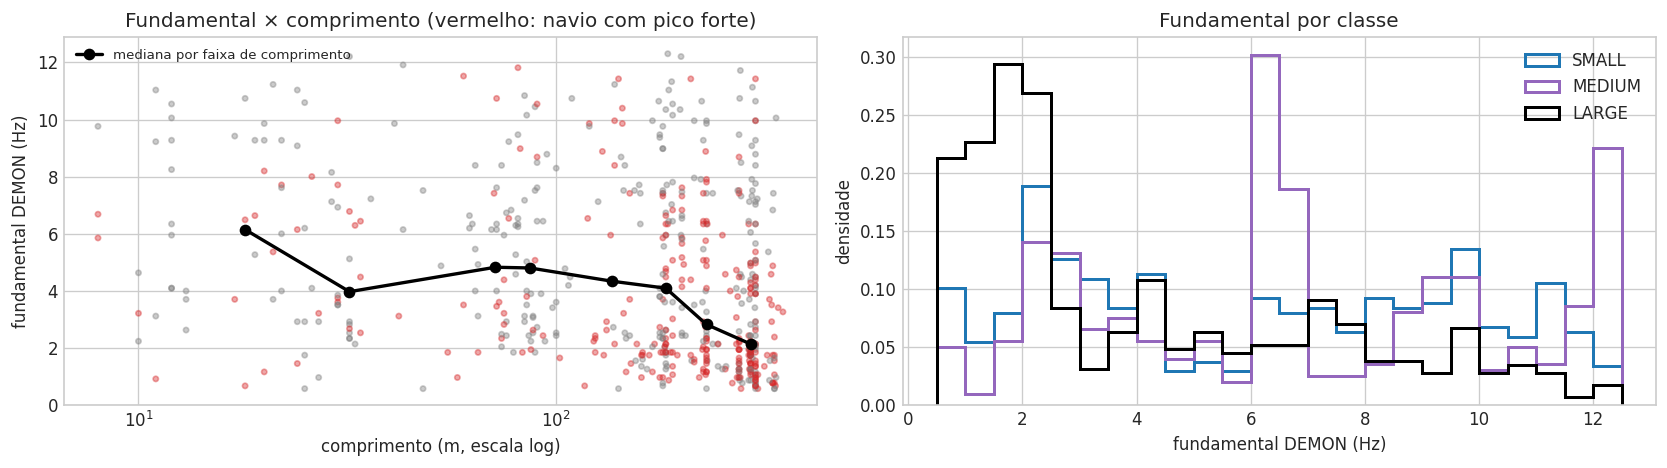

In [4]:
# Pico dominante de cada gravação: faixa de maior DEMON médio (dB acima do fundo) entre 0,5 e 25 Hz.
# Fundamental harmônica: a frequência f (0,5–12,5 Hz) cujos múltiplos f, 2f, 3f, 4f somam mais energia
# (tolerância de ±h faixas no h-ésimo múltiplo). O pico dominante pode ser o eixo, a passagem das pás (BPF) ou um
# harmônico; a fundamental tende a apontar a rotação do eixo, mas sem saber o número de pás isso não é garantido.
_k = FD >= 0.5
_ip = np.where(_k)[0][SD.values[:, _k].argmax(1)]
def fundamental(y, fmin=0.5, fmax=12.5, K=4):
    best, bf = -np.inf, np.nan
    for i0 in np.where((FD >= fmin) & (FD <= fmax))[0]:
        s = []
        for h in range(1, K + 1):
            j = int(round((h * FD[i0] - FD[0]) / DF))
            if j >= len(FD):
                break
            s.append(y[max(j - h, 0):j + h + 1].max())
        if len(s) >= 2 and np.mean(s) > best:
            best, bf = np.mean(s), FD[i0]
    return bf
PK = pd.DataFrame({'f pico (Hz)': FD[_ip], 'altura (dB)': SD.values[np.arange(len(SD)), _ip],
                   'persistência do pico': PD.values[np.arange(len(PD)), _ip],
                   'fundamental (Hz)': [fundamental(SD.loc[i].values) for i in SD.index]}, index=SD.index)
PK['pico forte'] = PK['altura (dB)'] >= 10
PK = PK.join(LAB.map(CLS).rename('classe')).join(meta[['Ship ID', 'Length', 'DETAILED TYPE']])

POR_CLASSE = PK.groupby('classe').agg(**{'f pico mediana (Hz)': ('f pico (Hz)', 'median'),
                                         'fundamental mediana (Hz)': ('fundamental (Hz)', 'median'),
                                         'altura mediana (dB)': ('altura (dB)', 'median'),
                                         '% com pico forte (>= 10 dB)': ('pico forte', lambda x: 100 * x.mean())}).loc[['SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND']]
print('Pico dominante por classe (todas as gravações):'); display(POR_CLASSE.round(2))
_bins = [0, 2, 4, 6, 8, 12, 16, 25.1]
DIST_F = pd.crosstab(pd.cut(PK['fundamental (Hz)'], _bins), PK.classe, normalize='columns')[['SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND']] * 100
print('Onde cai a fundamental (% das gravações):'); display(DIST_F.round(1))

# fundamental × comprimento, um ponto por navio (só navios)
_n = PK[PK.classe.isin(['SMALL', 'MEDIUM', 'LARGE'])].dropna(subset=['Length']).groupby('Ship ID').agg(
    f=('fundamental (Hz)', 'median'), fp=('f pico (Hz)', 'median'), L=('Length', 'first'), forte=('pico forte', 'mean'))
RHO_F = spearmanr(_n.f, _n.L); RHO_FP = spearmanr(_n.fp, _n.L)
_nf = _n[_n.forte >= 0.5]
RHO_FF = spearmanr(_nf.f, _nf.L)
print(f'Spearman, por navio: fundamental × comprimento ρ = {RHO_F[0]:.3f} (p = {RHO_F[1]:.1e}, n = {len(_n)}); '
      f'pico × comprimento ρ = {RHO_FP[0]:.3f}; só navios com pico forte: ρ = {RHO_FF[0]:.3f} (n = {len(_nf)})')
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].scatter(_n.L, _n.f, s=10, alpha=0.4, c=np.where(_n.forte >= 0.5, 'tab:red', 'tab:gray'))
_lb = pd.cut(_n.L, [0, 25, 50, 75, 100, 150, 200, 250, 400])
LEN_F = _n.groupby(_lb, observed=True).agg(navios=('f', 'size'), **{'fundamental mediana (Hz)': ('f', 'median')})
LEN_F.index = [f'{int(iv.left)}–{int(iv.right)} m' for iv in LEN_F.index]
print('Fundamental mediana por faixa de comprimento (por navio):'); display(LEN_F.round(2).T)
ax[0].plot(_n.groupby(_lb, observed=True).L.median(), _n.groupby(_lb, observed=True).f.median(), 'k-o', lw=2, label='mediana por faixa de comprimento')
ax[0].set_xscale('log'); ax[0].set_xlabel('comprimento (m, escala log)'); ax[0].set_ylabel('fundamental DEMON (Hz)')
ax[0].set_title('Fundamental × comprimento (vermelho: navio com pico forte)'); ax[0].legend(fontsize=8)
for c, cor in (('SMALL', 'tab:blue'), ('MEDIUM', 'tab:purple'), ('LARGE', 'k')):
    ax[1].hist(PK[PK.classe == c]['fundamental (Hz)'], bins=np.arange(0.5, 12.6, 0.5), density=True, histtype='step', lw=1.8, color=cor, label=c)
ax[1].set_xlabel('fundamental DEMON (Hz)'); ax[1].set_ylabel('densidade'); ax[1].legend(); ax[1].set_title('Fundamental por classe')
plt.tight_layout(); plt.show()

**Leitura.**
- **Por classe:** a fundamental mediana é 6,3 Hz nas SMALL, 6,4 Hz nas MEDIUM e 2,4 Hz nas LARGE; o pico forte aparece em 28%, 24% e 49% das gravações, e em 8% do BACKGROUND. **SMALL e MEDIUM são iguais no DEMON**, como no LOFAR: mesma fundamental e mesma fração de picos fortes. Só as LARGE se destacam, com modulação mais grave e mais forte.
- **Fundamental × comprimento:** quanto maior o navio, mais baixa a fundamental (ρ = -0,31, p < 0,001, 586 navios; só navios com pico forte: ρ = -0,33, 277 navios). É o sentido esperado fisicamente (hélices maiores giram mais devagar), mas a relação é moderada: navios de mesmo tamanho têm fundamentais bem diferentes (velocidade, número de pás, tipo de propulsão).
- **Mas a relação não é gradual:** a fundamental mediana fica entre 4,0 e 4,8 Hz de 25 a 200 m e só cai acima de 200 m (200–250 m: 2,8 Hz; 250–400 m: 2,1 Hz). O DEMON distingue os navios **muito grandes**, não os pequenos dos médios.
- 
- **Cautela:** sem saber o número de pás, não dá para dizer se a fundamental é o eixo ou a passagem das pás; o pico dominante muitas vezes é um harmônico.

## 3. Acertadas × erradas, por destino

In [5]:
# Acertadas × erradas por destino: medianas e comparação por navio (Mann-Whitney contra as acertadas)
X = T.join(PK[['f pico (Hz)', 'fundamental (Hz)', 'altura (dB)', 'persistência do pico', 'pico forte']])
_med = X.groupby(['subgrupo', 'Ship ID'])[['f pico (Hz)', 'fundamental (Hz)', 'altura (dB)', 'persistência do pico', 'pico forte']].median().reset_index()
_a = _med[_med.subgrupo == 'acertada']
_rows = []
for s in SUBS:
    x = _med[_med.subgrupo == s]; g = X[X.subgrupo == s]
    r = {'subgrupo': s, 'gravações': len(g), 'navios': len(x), '% gravações com pico forte': 100 * g['pico forte'].mean()}
    for c in ('f pico (Hz)', 'fundamental (Hz)', 'altura (dB)', 'persistência do pico'):
        r[f'{c}: mediana'] = g[c].median()
        if s != 'acertada':
            U, p = mannwhitneyu(x[c], _a[c]); r[f'{c}: AUC'] = U / (len(x) * len(_a)); r[f'{c}: p'] = p
    _rows.append(r)
SUB = pd.DataFrame(_rows).set_index('subgrupo')
print('AUC = probabilidade de um navio do subgrupo ter valor maior que um navio acertado (0,5 = sem diferença):')
display(SUB.round(3).T)

AUC = probabilidade de um navio do subgrupo ter valor maior que um navio acertado (0,5 = sem diferença):


subgrupo,acertada,errada→SMALL,errada→MEDIUM,errada→BACKGROUND
gravações,265.00,5.60e+01,42.00,2.30e+01
navios,214.00,5.20e+01,37.00,2.30e+01
% gravações com pico forte,66.04,2.14e+01,16.67,1.30e+01
f pico (Hz): mediana,4.30,6.98e+00,3.86,1.08e+01
fundamental (Hz): mediana,2.05,5.57e+00,5.42,6.84e+00
altura (dB): mediana,11.78,6.31e+00,6.01,4.16e+00
persistência do pico: mediana,0.74,3.79e-01,0.43,2.68e-01
f pico (Hz): AUC,NaN,6.55e-01,0.50,6.81e-01
f pico (Hz): p,NaN,1.00e-03,0.95,4.00e-03
fundamental (Hz): AUC,NaN,7.29e-01,0.62,7.40e-01


**Leitura.**
- Acertadas: fundamental mediana 2,1 Hz, altura 11,8 dB, 66% com pico forte.
- **errada→SMALL** (52 navios): fundamental mediana 5,6 Hz (AUC 0,73, p < 0,001), altura 6,3 dB (AUC 0,15, p < 0,001), 21% com pico forte: o pico é mais fraco que nas acertadas; a fundamental é mais alta.
- **errada→MEDIUM** (37 navios): fundamental mediana 5,4 Hz (AUC 0,63, p = 0,015), altura 6,0 dB (AUC 0,17, p < 0,001), 17% com pico forte: o pico é mais fraco que nas acertadas; a fundamental é mais alta.
- **errada→BACKGROUND** (23 navios): fundamental mediana 6,8 Hz (AUC 0,74, p < 0,001), altura 4,2 dB (AUC 0,10, p < 0,001), 13% com pico forte: o pico é mais fraco que nas acertadas; a fundamental é mais alta.

## 4. O pico forte como pista do modelo

Para todas as gravações de navio: em que fração dos folds o BiGRU DEMON prevê LARGE, conforme a gravação tenha ou não um pico forte?

In [6]:
# O pico forte como pista do modelo: em que fração dos folds a gravação é prevista como LARGE, sem e com pico forte?
_dd = pd.concat(R.file_predictions(MODELO).values()); _dd['File'] = _dd.File.astype(int)
_t = _dd.assign(L=_dd.Prediction == CID['LARGE']).groupby('File').agg(L=('L', 'mean'), Target=('Target', 'first'))
_t = _t[_t.Target != CID['BACKGROUND']].join(PK[['pico forte']]); _t['classe'] = _t.Target.map(CLS)
PISTA = (100 * _t.groupby(['classe', 'pico forte']).L.mean().unstack()).rename(
    columns={False: '% prevista LARGE, sem pico forte', True: '% prevista LARGE, com pico forte'})
PISTA.columns.name = None
PISTA['% das gravações com pico forte'] = 100 * _t.groupby('classe')['pico forte'].mean()
PISTA = PISTA.loc[['SMALL', 'MEDIUM', 'LARGE']]
FRAC_LARGE_FORTE = 100 * (_t[_t['pico forte']].classe == 'LARGE').mean()
display(PISTA.round(1))
print(f'Das gravações de navio com pico forte, {FRAC_LARGE_FORTE:.0f}% são LARGE.')

,"% prevista LARGE, sem pico forte","% prevista LARGE, com pico forte",% das gravações com pico forte
classe,,,
SMALL,16.8,42.1,27.9
MEDIUM,8.7,22.8,24.4
LARGE,48.2,78.5,49.1


Das gravações de navio com pico forte, 55% são LARGE.


**Leitura.** Em qualquer classe, ter um pico forte aumenta a chance de a gravação ser chamada de LARGE (SMALL de 17% para 42%; MEDIUM de 9% para 23%; LARGE de 48% para 78%). Como a banda de 31–86 Hz no LOFAR, o pico forte é uma pista de LARGE para o modelo, mas fraca de tamanho real: aparece em 49% das LARGE, 28% das SMALL e 24% das MEDIUM, e das gravações com pico forte só 55% são LARGE.

## 5. Relação com a banda LOFAR de 31–86 Hz

Fração das gravações com pico forte no DEMON, conforme tenham ou não o pico grave do LOFAR na banda de 31–86 Hz (NB35):

In [7]:
# Relação com a banda LOFAR de 31–86 Hz (NB35): o pico forte do DEMON e a banda grave aparecem juntos?
_S = pd.read_pickle(os.path.join(R.ROOT, 'data', 'iara_processed', 'cache_lofar_espectro_medio.pkl'))
_F = (np.arange(1024) + 1) * 16000 / 2048
_kp = (_F >= 20) & (_F <= 250)
_pl = pd.Series(_F[np.where(_kp)[0][_S.values[:, _kp].argmax(1)]], index=_S.index)
Y = PK[PK.classe.isin(['SMALL', 'MEDIUM', 'LARGE'])].join(_pl.between(31, 86, inclusive='left').rename('banda LOFAR'))
JUNTOS = (100 * Y.groupby(['classe', 'banda LOFAR'])['pico forte'].mean()).unstack('banda LOFAR').reindex(columns=[False, True])
JUNTOS.columns = ['sem a banda LOFAR', 'com a banda LOFAR']
print('% das gravações com pico forte no DEMON:')
display(JUNTOS.loc[['SMALL', 'MEDIUM', 'LARGE']].round(1))
RHO_LOFAR = spearmanr(Y['fundamental (Hz)'], _S.loc[Y.index, (_F >= 31) & (_F < 86)].mean(1))
print(f'Spearman entre a fundamental DEMON e o nível da banda LOFAR 31–86 Hz (todas as gravações de navio): '
      f'ρ = {RHO_LOFAR[0]:.3f} (p = {RHO_LOFAR[1]:.1e})')

% das gravações com pico forte no DEMON:


,sem a banda LOFAR,com a banda LOFAR
classe,,
SMALL,26.1,30.4
MEDIUM,23.0,27.1
LARGE,30.8,56.2


Spearman entre a fundamental DEMON e o nível da banda LOFAR 31–86 Hz (todas as gravações de navio): ρ = -0.270 (p = 1.5e-25)


**Leitura.** SMALL: 26% sem a banda e 30% com a banda; MEDIUM: 23% sem a banda e 27% com a banda; LARGE: 31% sem a banda e 56% com a banda. A fundamental DEMON cai quando a banda LOFAR é mais forte (ρ = -0,27, p < 0,001). A associação é forte nas LARGE e fraca nas SMALL e MEDIUM (poucos pontos percentuais). As duas pistas aparecem juntas: gravações com a banda grave no LOFAR têm mais vezes um pico forte e mais grave no DEMON. Elas podem refletir o mesmo regime da hélice (cavitação mais intensa e rotação mais baixa), o que poderia explicar por que os modelos LOFAR e DEMON tendem a errar nas mesmas direções (não verificado aqui).

### 5.1 Sensibilidade ao limiar de pico forte

O limiar de 10 dB é uma escolha. As mesmas medidas com 6, 8, 12 e 15 dB acima do fundo:

In [8]:
# Sensibilidade ao limiar de "pico forte" (6, 8, 10, 12 e 15 dB acima do fundo)
_pl = _dd.assign(L=_dd.Prediction == CID['LARGE']).groupby('File').L.mean()
_lab = LAB.map(CLS)
def _grupos(c):
    x = pd.concat(R.file_predictions(MODELO).values()); x['File'] = x.File.astype(int); x = x[x.Target == CID[c]]
    t = x.groupby('File').apply(lambda g: (g.Prediction == g.Target).mean(), include_groups=False)
    dst = x[x.Prediction != CID[c]].groupby('File').Prediction.agg(lambda v: v.value_counts().index[0]).map(CLS)
    g = pd.Series(np.where(t == 1, 'acertada', np.where(t == 0, 'errada', 'oscila')), index=t.index)
    return pd.Series(np.where(g == 'errada', 'errada→' + dst.reindex(t.index).fillna('?'), g), index=t.index)
_G = {c: _grupos(c) for c in ('SMALL', 'MEDIUM', 'LARGE')}
_SUBS_S = {'LARGE': ['acertada', 'errada→SMALL', 'errada→MEDIUM'], 'MEDIUM': ['acertada', 'errada→LARGE', 'errada→SMALL'],
           'SMALL': ['acertada', 'errada→LARGE', 'errada→MEDIUM']}
_banda = Y['banda LOFAR']
_rows = []
for th in (6, 8, 10, 12, 15):
    fx = PK['altura (dB)'] >= th
    r = {'limiar (dB)': th}
    for c in ('SMALL', 'MEDIUM', 'LARGE', 'BACKGROUND'):
        r[f'% com pico forte: {c}'] = 100 * fx[_lab.index[_lab == c]].mean()
    for c in ('SMALL', 'MEDIUM', 'LARGE'):
        ids = _lab.index[_lab == c]
        r[f'{c}: % prevista LARGE, sem → com'] = f"{100 * _pl[ids][~fx[ids]].mean():.0f} → {100 * _pl[ids][fx[ids]].mean():.0f}"
    nv = _lab.index[_lab != 'BACKGROUND']
    r['% LARGE entre as gravações com pico forte'] = 100 * (_lab[nv][fx[nv]] == 'LARGE').mean()
    for c, sl in _SUBS_S.items():
        g = _G[c]
        r[f'{c} % com pico forte: ' + ' / '.join(x.replace('errada→', '→') for x in sl)] = ' / '.join(f"{100 * fx[g.index[g == x]].mean():.0f}" for x in sl)
    L = Y.index[Y.classe == 'LARGE']
    r['LARGE % com pico forte: sem / com banda LOFAR'] = f"{100 * fx[L][~_banda[L]].mean():.0f} / {100 * fx[L][_banda[L]].mean():.0f}"
    _rows.append(r)
SENS = pd.DataFrame(_rows).set_index('limiar (dB)').T
display(SENS)

limiar (dB),6,8,10,12,15
% com pico forte: SMALL,60.92,42.02,27.94,15.55,7.14
% com pico forte: MEDIUM,68.77,47.36,24.43,13.6,4.03
% com pico forte: LARGE,79.72,65.38,49.13,34.97,16.43
% com pico forte: BACKGROUND,16.48,12.64,8.43,6.13,3.07
"SMALL: % prevista LARGE, sem → com",11 → 32,14 → 37,17 → 42,20 → 44,22 → 52
"MEDIUM: % prevista LARGE, sem → com",9 → 14,8 → 16,9 → 23,9 → 31,10 → 60
"LARGE: % prevista LARGE, sem → com",30 → 72,40 → 75,48 → 78,54 → 79,60 → 81
% LARGE entre as gravações com pico forte,44.75,49.08,54.99,60.98,65.28
LARGE % com pico forte: acertada / →SMALL / →MEDIUM,93 / 54 / 50,82 / 36 / 36,66 / 21 / 17,47 / 12 / 14,22 / 2 / 5
MEDIUM % com pico forte: acertada / →LARGE / →SMALL,86 / 79 / 44,52 / 64 / 33,25 / 48 / 19,13 / 39 / 10,2 / 24 / 2


**Leitura.**
- Em todos os limiares, as LARGE têm mais pico forte que SMALL e MEDIUM, e SMALL e MEDIUM ficam sempre parecidas (diferença menor que 10 p.p.). Em todos os limiares e nas três classes, ter pico forte aumenta a chance de a gravação ser chamada de LARGE.
- Quanto mais alto o limiar, mais específico de LARGE é o pico forte (das gravações com pico forte, 45% são LARGE com 6 dB e 65% com 15 dB), mas mais raro (com 15 dB, só 16% das LARGE o têm).
- A única exceção: com 6 dB, as MEDIUM erradas→LARGE não têm mais pico forte que as acertadas. Com um limiar tão baixo, a maioria das gravações passa (69% das MEDIUM e 86% das MEDIUM acertadas) e a medida deixa de discriminar; a partir de 8 dB a diferença aparece.
- **As conclusões não dependem do limiar de 10 dB**, que fica no meio da faixa testada.

## 6. Navios conhecidos e tipos de navio

In [9]:
# Taxa de acerto do BiGRU DEMON conforme o número de gravações do navio (esta classe e LARGE, para comparação)
def por_tamanho(Tx):
    n = Tx['Ship ID'].map(Tx.groupby('Ship ID').size())
    fx = pd.cut(n, [0, 1, 3, 10, 10000], labels=['1', '2–3', '4–10', 'mais de 10'])
    t = (pd.crosstab(fx, Tx.grupo, normalize='index') * 100).reindex(columns=['acertada', 'oscila', 'errada'], fill_value=0)
    return t.join(Tx.groupby(fx, observed=True).agg(gravações=('grupo', 'size'), navios=('Ship ID', 'nunique')))
_tl = taxa_acerto(MODELO, CID['LARGE'])
_TL = pd.DataFrame({'grupo': grupo(_tl)}).join(meta[['Ship ID']])
TAM = pd.concat({CLASSE: por_tamanho(T), 'LARGE': por_tamanho(_TL)} if CLASSE != 'LARGE' else {CLASSE: por_tamanho(T)}, axis=0)
display(TAM.round(1))

# Tipos de navio da classe (pelo menos 10 gravações): acerto e pico dominante
TIPOS = X.groupby('DETAILED TYPE').agg(gravações=('grupo', 'size'), navios=('Ship ID', 'nunique'),
                                       pct_acertada=('grupo', lambda g: 100 * (g == 'acertada').mean()),
                                       pct_errada=('grupo', lambda g: 100 * (g == 'errada').mean()),
                                       fundamental=('fundamental (Hz)', 'median'), altura=('altura (dB)', 'median'),
                                       forte=('pico forte', lambda g: 100 * g.mean()))
TIPOS = TIPOS[TIPOS.gravações >= 10].sort_values('gravações', ascending=False).rename(columns={
    'pct_acertada': '% acertada', 'pct_errada': '% errada', 'fundamental': 'fundamental mediana (Hz)',
    'altura': 'altura mediana (dB)', 'forte': '% com pico forte'})
print('Tipos de navio:'); display(TIPOS.round(1))

acertada  oscila  errada  gravações  navios
      Ship ID                                                
LARGE 1               47.4    30.8    21.8        331     331
      2–3             44.7    32.4    22.9        170      76
      4–10            22.9    48.6    28.6         35       8
      mais de 10      66.7    33.3     0.0         36       2

Tipos de navio:


,gravações,navios,% acertada,% errada,fundamental mediana (Hz),altura mediana (dB),% com pico forte
DETAILED TYPE,,,,,,,
Bulk Carrier,189,161,49.2,16.9,2.4,11.6,56.6
Container Ship,140,88,45.7,20.0,3.9,8.8,42.1
Crude Oil Tanker,60,47,61.7,16.7,2.0,10.4,56.7
Oil/Chemical Tanker,52,37,30.8,23.1,3.0,10.9,57.7
General Cargo,32,30,40.6,34.4,4.0,8.8,46.9
Suction Dredger,22,4,86.4,9.1,2.1,8.7,27.3
Passenger Ship,15,9,13.3,60.0,6.4,7.9,13.3
LPG Tanker,14,6,14.3,35.7,3.0,10.5,57.1
Ore Carrier,12,11,66.7,8.3,1.8,10.9,66.7


**Leitura.**
- navios com 1 gravação: 47% acertadas (331 gravações); navios com 2–3 gravações: 45% acertadas (170 gravações); navios com 4–10 gravações: 23% acertadas (35 gravações); navios com mais de 10 gravações: 67% acertadas (36 gravações).
- Só 2 navios têm mais de 10 gravações, poucos para concluir algo sobre navios conhecidos; nos demais, o acerto não cresce com o número de gravações.
- Tipos com mais gravações: Bulk Carrier (161 navios): 49% acertadas, fundamental 2,4 Hz, 57% com pico forte; Container Ship (88 navios): 46% acertadas, fundamental 3,9 Hz, 42% com pico forte; Crude Oil Tanker (47 navios): 62% acertadas, fundamental 2,0 Hz, 57% com pico forte; Oil/Chemical Tanker (37 navios): 31% acertadas, fundamental 3,0 Hz, 58% com pico forte; General Cargo (30 navios): 41% acertadas, fundamental 4,0 Hz, 47% com pico forte.

## 7. Exemplos

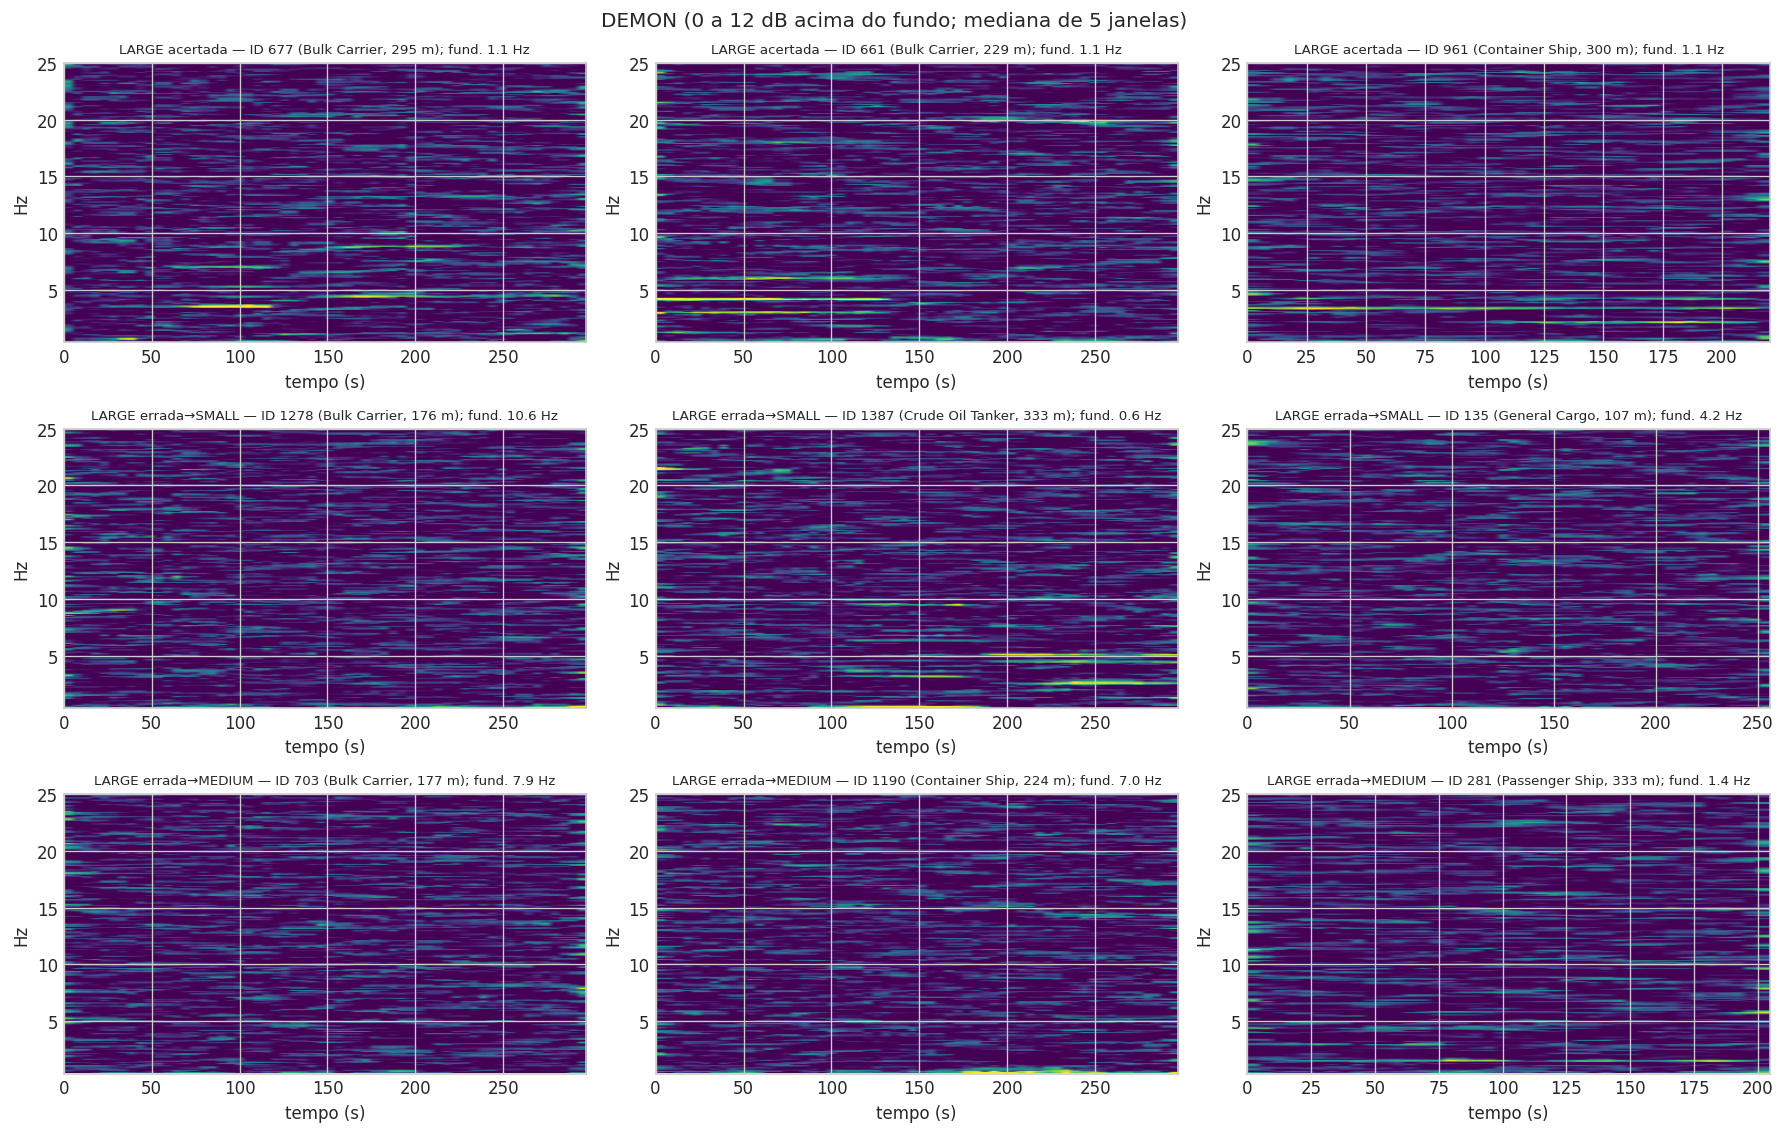

In [10]:
# Espectrogramas DEMON (dB acima do fundo, por janela de 10,24 s) de gravações sorteadas: acertadas e erradas
_rng = np.random.default_rng(1)
_lin = [s for s in SUBS][:3]
fig, ax = plt.subplots(len(_lin), 3, figsize=(15, 3.2 * len(_lin)))
for r, s in enumerate(_lin):
    pool = T.index[T.subgrupo == s]
    for c, i in enumerate(_rng.choice(pool, min(3, len(pool)), replace=False)):
        W = pd.read_pickle(os.path.join(DEMON_DIR, f'{i}.pkl'))['df'].values
        Wm = ndi.median_filter(W, size=(5, 1), mode='nearest')
        Z = 20 * np.log10(Wm / (fundo_tpsw(Wm) + 1e-12))
        ax[r, c].imshow(Z.T, aspect='auto', origin='lower', extent=[0, len(Z) * 5.12, FD[0], FD[-1]], vmin=0, vmax=12, cmap='viridis')
        ax[r, c].set_title(f'{CLASSE} {s} — ID {i} ({meta.loc[i, "DETAILED TYPE"]}, {meta.loc[i, "Length"]:.0f} m); '
                           f'fund. {PK.loc[i, "fundamental (Hz)"]:.1f} Hz', fontsize=8)
        ax[r, c].set_xlabel('tempo (s)'); ax[r, c].set_ylabel('Hz')
fig.suptitle('DEMON (0 a 12 dB acima do fundo; mediana de 5 janelas)'); plt.tight_layout(); plt.show()

## 8. Conclusões parciais

1. **A média faixa a faixa não separa as classes no DEMON**: cada navio tem as suas linhas em frequências próprias. A informação está no **pico de cada gravação**.
2. **A fundamental cai com o comprimento** (ρ = -0,31), no sentido físico esperado, mas só nos navios acima de ~200 m; de 25 a 200 m ela fica praticamente constante, e a dispersão entre navios de mesmo tamanho é grande.
3. **LARGE acertadas × erradas:** errada→SMALL: o pico é mais fraco que nas acertadas; a fundamental é mais alta; errada→MEDIUM: o pico é mais fraco que nas acertadas; a fundamental é mais alta; errada→BACKGROUND: o pico é mais fraco que nas acertadas; a fundamental é mais alta.
4. **O pico forte é uma pista de LARGE para o modelo**, como a banda de 31–86 Hz no LOFAR, e também fraca de tamanho real (aparece em 28% das SMALL e 24% das MEDIUM). As duas pistas tendem a aparecer juntas.
5. **Navios conhecidos:** sem evidência de que o acerto venha de navios repetidos.

**Ressalva:** os modelos DEMON são bem mais fracos que os LOFAR (SP ~55 contra ~66), então os rótulos de acerto e erro são mais ruidosos. A relação entre fundamental e comprimento, que não depende do modelo, é o resultado mais sólido deste notebook.